# 04-动态与静态任务创建、参数及命名规范


## 1. 本篇内容与学习目标

本篇是《FreeRTOS 从入门到实战》十七篇笔记中的第04篇，对应以下三份课程PPT，按原课顺序整理。

| 课程PPT | 主题 | 学习目标 |
|---|---|---|
| `06task任务创建.pptx` | 动态任务创建与参数传递 | 区分任务入口与裸机函数，理解六个参数，完成双LED任务创建与调度 |
| `07静态任务创建.pptx` | 用户提供任务内存 | 准备任务栈和控制块，开启静态分配，提供Idle、Timer任务所需内存 |
| `08freeRTOS命名规范.pptx` | 类型、变量、函数和宏命名 | 从名称识别类型与用途，并结合声明判断实际接口 |

承接第03篇已移植的GD32工程，本篇重点从“让内核运行起来”转向“正确创建和配置任务”。代码保留课件参数，放在Markdown中供阅读、对照；板级驱动、配置及示意代码需要放回实际工程。


## 2. 任务入口与裸机函数：不能普通返回

在课件所示的裸机轮询流程中，主循环依次调用各个处理函数。一个函数完成本次工作后返回，后面的函数才能继续执行；若它卡在无限循环里，后续处理就无法进行。

FreeRTOS任务入口由调度器运行，不能像普通被调用函数一样执行完后直接返回。课程中的LED任务用 `while(1)` 持续处理业务，并通过延时让调度器安排其他任务。

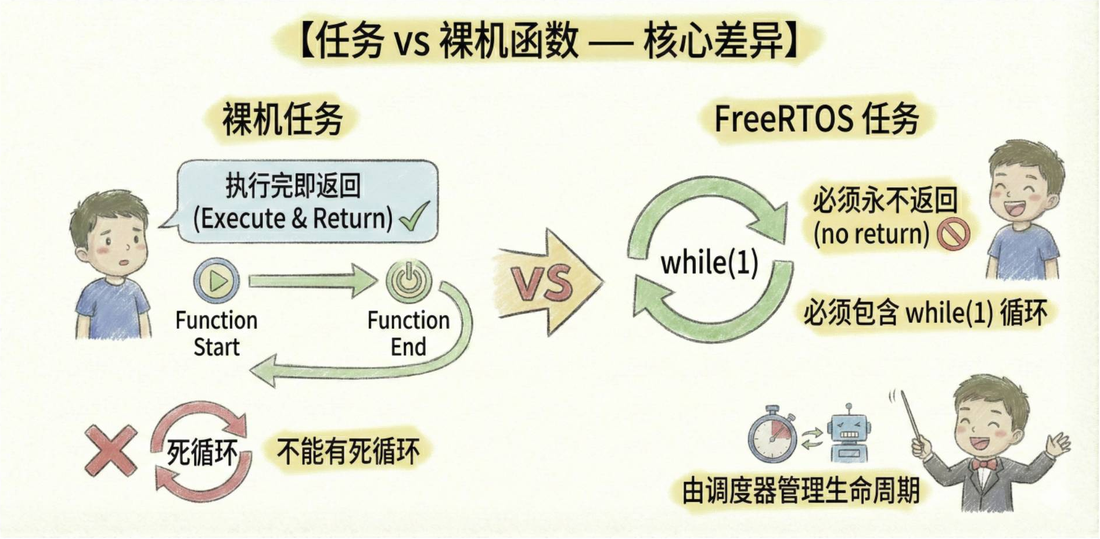

任务函数采用以下接口形式：

```c
void func(void *param);
```

它没有返回值，接收一个通用指针参数。创建任务时传入的是这个函数的地址，不是提前调用函数。

> 边界补充：图中的“裸机不能有死循环”针对被主循环调用的处理函数，裸机的主循环本身当然可以无限循环。任务入口的核心约束是**不能普通return或运行到函数末尾**；有限工作任务可通过任务删除机制结束自身，本篇只保留课件的持续运行写法。


## 3. xTaskCreate的六个参数

`xTaskCreate()` 为新任务动态申请内存，并把任务加入就绪集合。它需要任务控制块和任务栈两类内存，分配由内核完成。

课件按以下顺序解释参数。

| 顺序 | 参数 | 类型与含义 | 本课注意事项 |
|---|---|---|---|
| 1 | 任务函数 | `TaskFunction_t`，指向 `void func(void *param)` | 入口不能普通返回 |
| 2 | 任务名称 | `const char *`，便于调试辨认 | 名称存储容量由 `configMAX_TASK_NAME_LEN` 决定 |
| 3 | 栈深度 | 课件表中为 `uint16_t`，表示栈元素个数 | 不是字节数；字节数为深度乘 `sizeof(StackType_t)` |
| 4 | 任务参数 | `void *`，传给入口函数 | 无额外参数时传 `NULL` |
| 5 | 任务优先级 | `UBaseType_t` | 数字越大优先级越高，范围为0到 `configMAX_PRIORITIES - 1` |
| 6 | 句柄输出地址 | `TaskHandle_t *` | 传入句柄变量的地址；无需保存句柄时可传 `NULL` |

为了看清参数关系，下面列出经官方V10.5.1头文件核对的声明；它是参考版本的接口，不代表课程源码版本已确认。

```c
BaseType_t xTaskCreate(
    TaskFunction_t pxTaskCode,
    const char * const pcName,
    const configSTACK_DEPTH_TYPE usStackDepth,
    void * const pvParameters,
    UBaseType_t uxPriority,
    TaskHandle_t * const pxCreatedTask
);
```

> 类型核对：参考版本使用 `configSTACK_DEPTH_TYPE`，未覆盖时为 `uint16_t`。课件中的类型对应一种配置，不能视为所有版本永远固定的类型。

当前Cortex-M4F端口的 `StackType_t` 为32位类型，因此：

```text
128个栈元素 × 4字节 = 512字节任务栈
```

这里的512字节只表示任务栈，不包含任务控制块和动态分配管理开销。

> 名称核对：课件标注 `configMAX_TASK_NAME_LEN` “默认10”，参考版本的内核默认值为16，工程也可自行配置。该容量包含结尾的 `\0`；配置为10时，完整保留的名称最多为9字节，过长名称会截断。以当前工程配置为准。


## 4. 动态创建task1：保存状态码与任务句柄

在完成LED等硬件初始化后，课件通过以下语句创建任务。创建调用放在 `main()` 的初始化流程或其他初始化函数内。

```c
// 1. 创建任务（动态任务创建）
// 创建task1，点亮和熄灭LED1
ret = xTaskCreate(
    task1,          // 任务函数
    "task1",        // 任务名字
    128,            // 128*4=512byte，根据任务内部内存使用情况定义
    NULL,           // 任务参数
    1,              // 中断优先级：0大、1小；task任务优先级：数字越大越高
    &task1Handler   // 任务的引用，后续可通过它操作任务
);
```

第五个参数 `1` 是**任务优先级**。原注释同时对比Cortex-M中断优先级的编号方向，不能把中断优先级直接套进任务优先级；本篇只处理任务参数。

课件截图没有展示 `ret` 和 `task1Handler` 的声明。对应类型为：

```c
BaseType_t ret;
TaskHandle_t task1Handler = NULL;
```

`ret` 表示创建是否成功，`task1Handler` 保存创建后的任务身份，二者用途不同。成功时 `ret == pdPASS`；后续操作该任务时使用句柄，而不是状态码。

> 返回值补充：动态创建内存不足时，参考版本返回 `errCOULD_NOT_ALLOCATE_REQUIRED_MEMORY`，不是固定返回 `pdFAIL`。判断成功应检查 `ret == pdPASS`，失败后处理内存问题，不能继续把未成功创建的句柄当有效任务使用。

若创建多个任务，应在**每次创建之后分别检查返回值**。复用 `ret` 却只检查最后一次，会丢失前一次的创建结果。还要确认 `configSUPPORT_DYNAMIC_ALLOCATION` 已启用，且第02、03篇加入的 `heap_4.c` 有足够堆空间。

本页示例使用栈深度128、优先级1；第03篇移植验证页使用64、优先级2。这里沿用本课参数，不把两份课件拼成同一段程序。


## 5. 启动调度器与双LED任务验证

### 5.1 创建后启动调度

在调度器尚未启动的初始化阶段，仅创建任务不会执行任务入口。准备任务并检查创建结果后，课件调用：

```c
vTaskStartScheduler();
```

正常启动后，控制权交给RTOS内核，由调度器运行任务；当前Cortex-M端口也在启动过程中接管SysTick，不能再用原裸机代码重新配置它。

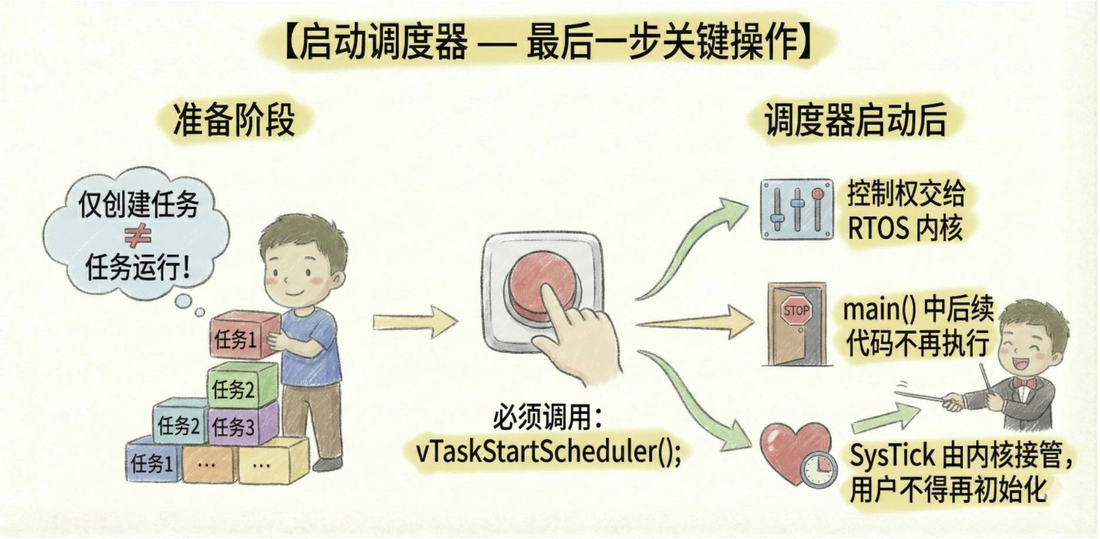

> 启动前提：图中的 `main()` 后续不再执行，指调度器正常启动的情况。若调用返回或任务未运行，应检查内核启动及Idle、Timer等任务的创建条件。调度器已经运行后再创建任务，新任务可能立即获得运行机会；“创建不运行”只描述图中的准备阶段。

### 5.2 本课的两个任务体

课件分别给出红灯、绿灯任务，保留原代码如下。

```c
void task1(void *pvParameters) {
    while(1) {
        bsp_leds_toggle(LED1);
        vTaskDelay(250);
    }
}
```

```c
void task2(void *pvParameters) {
    while(1) {
        bsp_leds_toggle(LED2);
        vTaskDelay(1000);
    }
}
```

每次 `bsp_leds_toggle()` 切换一次LED状态；正的 `vTaskDelay()` 延时使当前任务进入阻塞状态，等待期间不持续占用CPU。调度器安排其他就绪任务，应用不必手动切换。这与第03篇的轮询忙等示例不同。

> 时间单位：`vTaskDelay()` 接收**tick数**。课件把250、1000写成毫秒，隐含一个tick为1 ms，即 `configTICK_RATE_HZ == 1000`。需要表达毫秒时，可采用课件后续出现的 `vTaskDelay(pdMS_TO_TICKS(delay_ms))` 写法。

在上述节拍条件下，红灯名义上每250 ms切换一次、绿灯每1000 ms切换一次；完成一次亮灭循环约需500 ms与2000 ms。课件中的“闪烁周期”应结合切换动作理解，实际时间还受节拍相位、函数执行和调度影响。

创建两个任务并启动调度后，应观察到两灯持续以不同速度闪烁。这是课程的预期验证现象，本笔记未进行开发板实测。


## 6. 栈深度、优先级和句柄的配置陷阱

### 6.1 栈容量按任务实际用量设置

课件给出的经验是：简单任务采用128个栈元素，当前端口约512字节，通常可作为起点。含较大局部数组、大变量或较深函数调用时，需要增加栈容量，否则可能发生栈溢出。

这个经验不证明任意任务用512字节都足够。配置时要结合任务内部调用、局部变量和任务上下文所需空间。

课件提到可配合 `configCHECK_FOR_STACK_OVERFLOW` 调试。启用检查还需要提供匹配的 `vApplicationStackOverflowHook()`；第03篇为解决未使用钩子的链接问题将该宏设为0，这里不能只改开关而遗漏钩子实现。

### 6.2 优先级必须落在配置范围内

最大任务优先级为：

```text
configMAX_PRIORITIES - 1
```

若配置允许5个优先级，则合法值为0、1、2、3、4，而不是1到5。

课件说设为 `configMAX_PRIORITIES` 或更大会触发断言。参考内核确实用 `configASSERT(uxPriority < configMAX_PRIORITIES)` 检查，但能否停在断言处取决于工程是否配置了有效的 `configASSERT`。不能依赖关闭断言后的内部处理来接受越界值。

### 6.3 保存句柄，才能方便地指定任务

课件示例声明为：

```c
TaskHandle_t xRedTaskHandle;
```

创建时把 `&xRedTaskHandle` 交给动态创建接口，之后便可把有效句柄用于 `vTaskSuspend()`、`vTaskDelete()` 等API。这里只说明句柄用途，任务状态和生命周期操作由后续课程展开。


## 7. pvParameters：复用函数与保证参数生命周期

### 7.1 一个入口可以创建多个任务

两个LED任务若只在LED编号和延时时间上不同，分别复制一份任务函数会造成重复代码。课件通过任务参数表达差异，让同一入口函数创建多个任务，提高复用性与维护性。

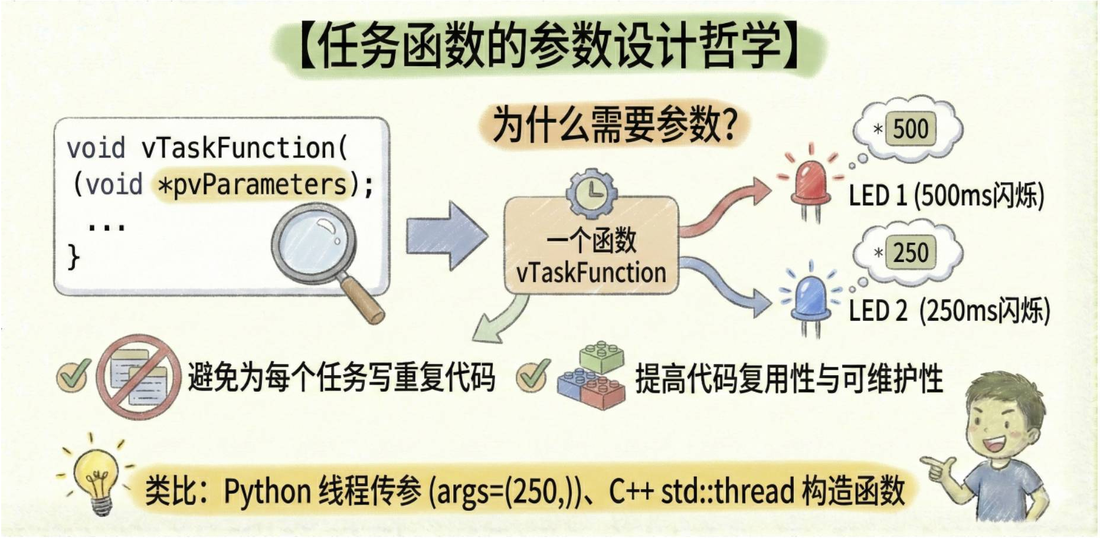

图中用LED1的500 ms、LED2的250 ms说明参数设计，与前面的双灯代码不是同一组时间配置。图中Python线程的 `args=(250,)`、C++的 `std::thread` 构造参数只是类比：创建时提供数据，入口在运行时读取它。

### 7.2 第四个参数是通用指针

`pvParameters` 对应 `xTaskCreate()` 的第四个参数，类型为 `void *`。任务入口接收到它后，根据约定恢复对象类型并读取内容。

**内核传递指针值，不替应用复制它指向的对象。** 如果传入某个对象的地址，该对象必须在任务访问期间仍然有效；创建函数返回成功不代表对象已被任务读取。

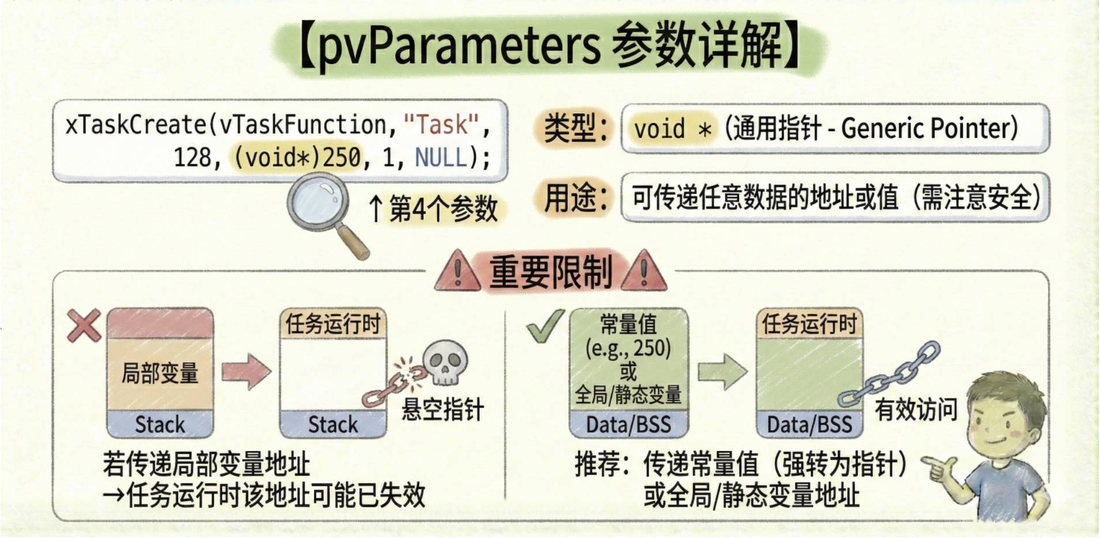

图中左侧说明悬空指针问题：把创建函数中的自动局部变量地址传给任务，创建函数返回后变量失效，任务再访问该地址就会出错。全局对象或 `static` 对象生命周期较长，可以避免这种失效。

> 范围补充：“不能传局部变量地址”应限定为任务访问时生命周期已经结束的自动局部对象。函数内的 `static` 变量仍有静态存储期，可以作为长期参数对象。堆上对象也可使用，但必须保证访问完成前不被释放。

图中右侧还把“常量值强转成指针”列为推荐做法；紧接着第13页将它列为误区。这个冲突在下一节结合原代码说明，不能把右侧示意直接当通用实现。


## 8. 传递整数常量的误区：值和对象地址不同

课件先指出，直接把普通整数填进指针参数会发生类型不匹配。下列是**反例示意**，省略号不是可编译调用。

```c
xTaskCreate(..., 250, ...); // error: int ≠ void*
```

然后把以下强转写法也标为“错误写法”，并展示如何在任务里转回整数。

```c
// 原课反例：把整数编码进指针值
xTaskCreate(vTaskBlink, "Red", 128, (void*)250, 1, NULL);
xTaskCreate(vTaskBlink, "Green", 128, (void*)1000, 1, NULL);
```

```c
// 原课反例的还原过程；HAL_GPIO_TogglePin(...)是示意占位
void vTaskBlink(void *pv) {
    uint32_t delay_ms = (uint32_t)pv; // 强转回整型
    while(1) {
        HAL_GPIO_TogglePin(...);
        vTaskDelay(pdMS_TO_TICKS(delay_ms));
    }
}
```

`(void*)250` 没有为250分配一个对象，也不是“指向存有250的变量”。这段还原过程转回指针值本身；如果把它当 `uint32_t *` 解引用，就会访问由250转换得到的地址。

> 课件核对：第12页推荐整数强转，第13、14页又反对它。整数与指针相互转换的结果依赖实现和位宽，在明确约束的平台上可以作为值编码，不能说所有强转都必然编译失败；它也不是通用、可移植的对象传参方式。这里保留课件反例，实际理解以“传有效对象地址、明确类型与生命周期”为准。

`HAL_GPIO_TogglePin(...)` 属于STM32 HAL风格示意，不能直接替换GD32工程的 `bsp_leds_toggle()` 并声称能编译。这个片段用于解释参数转换与 `pdMS_TO_TICKS()`，不构成完整LED实现。


## 9. 课件的参数实践建议与内存所有权

第14页按参数类型给出以下做法。表中的省略号用于表示创建参数中未展示的部分，均为教学片段。

| 场景 | 课件推荐片段 | 课件强调的点 |
|---|---|---|
| 简单数值：延时、ID、模式 | `uint32_t *p = pvPortMalloc(sizeof(uint32_t));`，再传 `p` | 避免 `(void*)value`，使用后释放 |
| 复杂结构体 | `MyStruct *s = pvPortMalloc(sizeof(MyStruct));`，再传 `s` | 让每个任务拥有独立参数副本，减少全局变量依赖 |
| 字符串 | `char *str = pvPortMalloc(len);`，`strcpy(str, "text");`，再传 `str` | 复制到可写内存 |
| 失效的自动局部对象 | `xTaskCreate(..., &local_var, ...)` | 创建函数返回后变量失效，任务访问产生未定义行为 |

动态分配参数与动态创建任务是两件事：`xTaskCreate()` 自动申请的是任务自身的栈和控制块，**不会自动释放应用传入的参数对象**。

以课件的数值参数为例，完整使用过程还需要以下步骤。

1. 检查 `pvPortMalloc()` 是否返回 `NULL`，成功后先给 `*p` 赋值，例如250。
2. 调用创建接口并检查是否返回 `pdPASS`。创建失败时，创建方释放参数对象。
3. 创建成功后，按约定由任务接管参数；创建方不能立即释放或再次释放它。
4. 若任务只需读取一次，任务可先通过 `*(uint32_t *)pvParameters` 复制数值到自己的局部变量，再调用 `vPortFree()` 释放堆对象；之后只使用已复制的数值。
5. 若任务持续使用该对象，必须让它一直有效，到不再访问时才释放。

复杂结构体也应先初始化；含内部指针时，还要保证指向的数据有效，“复制结构体”不等于自动复制其内部指针所指数据。

> 字符串补充：课件写“禁止传递字符串常量地址”，这个表述过于绝对。任务只读字符串时，生命周期足够长的字符串常量可以使用，并按 `const char *` 读取；需要修改字符时才应准备可写副本。复制 `"text"` 的容量至少为 `strlen("text") + 1`，包含结尾的 `\0`，分配失败后不能继续 `strcpy()`。

课件建议结构体避免全局变量，目的是隔离各任务的参数，不是禁止一切全局或静态对象。生命周期清楚、只读或有明确访问规则的静态对象同样可用于参数；禁止动态分配的项目则不能照搬本页的堆分配方案。

动态创建部分的课件小结强调：任务入口不返回，六个参数尤其要核对栈单位与优先级范围；准备好任务后启动调度，用不同延时观察并发执行，合理配置栈与优先级。


## 10. 动态与静态任务：内存由谁提供

第二份PPT首先对比任务的内存管理方式。

| 特性 | 动态任务：`xTaskCreate()` | 静态任务：`xTaskCreateStatic()` |
|---|---|---|
| 栈与控制块来源 | 内核从FreeRTOS heap申请 | 应用手动提供缓冲区 |
| 内存生命周期 | 内核负责任务自身内存的分配与回收 | 应用保证缓冲区有效并管理其生命周期 |
| heap依赖 | 依赖动态分配配置和堆容量 | 创建这个任务不需要从heap分配栈和控制块 |
| 课程使用建议 | 日常示例优先使用，代码较简洁 | 用于禁动态分配或要求确定内存布局的场景 |

课件将动态任务的释放归于 `vTaskDelete()`。在本系列采用的 `heap_4` 中，内核可回收动态任务内存；任务自删时，部分清理由Idle任务稍后完成。应用自行申请的参数内存仍须自行处理。

静态任务也要占用RAM。“没有该任务的heap依赖”只描述它的栈与控制块来源，不能由此断定整个应用都不使用动态内存。


## 11. xTaskCreateStatic：提供栈数组与控制块

### 11.1 接口与返回值

课件给出的原型如下。

```c
TaskHandle_t xTaskCreateStatic(
    TaskFunction_t pxTaskCode,
    const char * const pcName,
    const uint32_t ulStackDepth,
    void * const pvParameters,
    UBaseType_t uxPriority,
    StackType_t * const puxStackBuffer,
    StaticTask_t * const pxTaskBuffer
);
```

前五个参数用途与动态创建相同。最后两个参数变为应用提供的内存，句柄则通过返回值直接得到。

| 参数 | 应用需要提供什么 | 用途 |
|---|---|---|
| `puxStackBuffer` | 至少有 `ulStackDepth` 个元素的 `StackType_t` 数组 | 保存任务局部变量、函数调用及任务上下文所需栈内容 |
| `pxTaskBuffer` | 一个 `StaticTask_t` 对象的地址 | 为任务控制块TCB提供存储空间 |

TCB用于维护任务状态、优先级、栈指针等信息。应用使用 `StaticTask_t` 提供合适大小和对齐的存储，不需要手写内核控制块的成员。

`xTaskCreateStatic()` 成功时返回有效 `TaskHandle_t`，失败时返回 `NULL`，**不能拿返回的句柄与pdPASS比较**。无效缓冲区还可能触发已启用的断言，仍要先满足接口要求。

### 11.2 手动定义两类内存

在应用源文件的文件作用域中，课件定义：

```c
// 1. 任务栈：128元素，当前端口为512字节
StackType_t xTask1Stack[128];

// 2. 任务控制块（TCB）的存储
StaticTask_t xTask1TCB;
```

创建调用放在初始化函数内，保留课件示例：

```c
TaskHandle_t xTask1Handle = xTaskCreateStatic(
    vTask1, "Task1", 128, NULL, 1,
    xTask1Stack, &xTask1TCB
);
```

`vTask1` 是此静态示例使用的入口名，需要有对应的函数声明与实现。课件把内存定义和创建语句放在同一展示块中，这里分开标明位置；C语言中不能把函数调用写成文件作用域的普通运行语句。

数组和控制块要在任务使用期间持续有效，可放在全局或声明为 `static`。不要使用创建函数返回后失效的自动局部数组和控制块；函数内的局部 `static` 可以满足长期存储要求。

每个任务需要自己的栈和控制块，不能让两个仍在使用的任务共用同一块存储。传入的栈深度是128个元素，不是数组的512字节，也不能把 `sizeof(xTask1Stack)` 直接当元素数传入。


## 12. 启用静态分配及系统任务的内存回调

在现有工程的 `Middleware/FreeRTOS/Config/FreeRTOSConfig.h` 中，课件要求添加或确认：

```c
#define configSUPPORT_STATIC_ALLOCATION 1
```

未启用时，`xTaskCreateStatic()` 对应接口不参与条件编译；根据编译器和调用位置，可能出现声明问题或链接不到实现。开启后，应用不仅要准备自己的任务内存，还需要为内核的系统任务提供内存。

| 内存回调 | 提供给哪个任务 | 参考版本所需条件 |
|---|---|---|
| `vApplicationGetIdleTaskMemory()` | Idle空闲任务 | `configSUPPORT_STATIC_ALLOCATION == 1` |
| `vApplicationGetTimerTaskMemory()` | Timer软件定时器服务任务 | 静态分配已启用，且 `configUSE_TIMERS == 1` |

> 条件核对：课件统一说需要两个钩子，Timer回调还取决于是否启用软件定时器。官方V10.5.1在启用静态分配后，通过Idle内存回调静态创建空闲任务；启用定时器时，再通过Timer内存回调创建服务任务。实际接口与条件应对照工程所用版本。

这些函数用于**输出内存地址和栈深度**，不同于第03篇关闭的 `vApplicationIdleHook()` 等运行期钩子。即使 `configUSE_IDLE_HOOK == 0`，也不会取消静态创建Idle任务所需的内存回调。

把回调定义放在参与编译的应用源文件中，例如工程已有的钩子源文件或 `main.c`；不要把同一函数在多个源文件中重复定义。应用源文件需能包含 `FreeRTOS.h`、`task.h` 等相关声明。

如果仍保留动态创建任务，`configSUPPORT_DYNAMIC_ALLOCATION` 也要保持启用；静态和动态分配可以同时支持。仅开启静态支持不会自动把所有应用任务改成静态任务。


## 13. 为Idle任务提供长期有效的内存

课件的Idle内存回调如下，两个缓冲区定义在文件作用域。

```c
StaticTask_t idle_task_tcb;
StackType_t idle_task_stack[configMINIMAL_STACK_SIZE];

void vApplicationGetIdleTaskMemory(
    StaticTask_t **ppxIdleTaskTCBBuffer,
    StackType_t **ppxIdleTaskStackBuffer,
    uint32_t *pulIdleTaskStackSize)
{
    *ppxIdleTaskTCBBuffer = &idle_task_tcb;
    *ppxIdleTaskStackBuffer = idle_task_stack;
    *pulIdleTaskStackSize = configMINIMAL_STACK_SIZE;
}
```

调用方把用于接收结果的变量地址传入。回调通过双重指针写出TCB地址和栈数组首地址，通过 `uint32_t *` 写出栈深度。

| 赋值 | 输出内容 |
|---|---|
| `*ppxIdleTaskTCBBuffer = &idle_task_tcb` | 控制块存储对象地址 |
| `*ppxIdleTaskStackBuffer = idle_task_stack` | 栈数组首元素地址 |
| `*pulIdleTaskStackSize = configMINIMAL_STACK_SIZE` | 栈元素个数 |

回调返回后，内核仍要使用这些存储，因此不能在函数内临时定义自动局部缓冲区。栈大小输出也不能改成 `sizeof(idle_task_stack)`，后者得到的是字节数，会与数组实际元素数不一致。


## 14. 为Timer服务任务提供独立内存

开启软件定时器时，课件为Timer任务提供另一套缓冲区，不能与Idle共用。

```c
StaticTask_t timer_task_tcb;
StackType_t timer_task_stack[configTIMER_TASK_STACK_DEPTH];

void vApplicationGetTimerTaskMemory(
    StaticTask_t **ppxTimerTaskTCBBuffer,
    StackType_t **ppxTimerTaskStackBuffer,
    uint32_t *pulTimerTaskStackSize)
{
    *ppxTimerTaskTCBBuffer = &timer_task_tcb;
    *ppxTimerTaskStackBuffer = timer_task_stack;
    *pulTimerTaskStackSize = configTIMER_TASK_STACK_DEPTH;
}
```

这里用 `configTIMER_TASK_STACK_DEPTH` 同时定义数组长度和输出深度，保持缓冲区容量与内核收到的元素数一致。Timer任务的内存也要长期存在。

当 `configUSE_TIMERS == 0` 时，参考版本不创建这个服务任务，不需要为此无条件增加一套Timer缓冲区。本节只整理静态内存接口，软件定时器的创建与运行由后面的课程讲解。


## 15. 静态任务演示与适用场景

课件的静态演示描述为：**红灯1 s、绿灯250 ms，独立闪烁**。这里的颜色与时间对应关系与第一份PPT的红灯250 ms、绿灯1000 ms不同，保留各自的描述。

这页未展示完整静态双LED工程，不能只根据一句效果描述恢复全部任务代码。它要说明的是：在任务体和调度设置相同的条件下，动态或静态创建改变的是内存来源，任务仍由同一调度器安排运行。

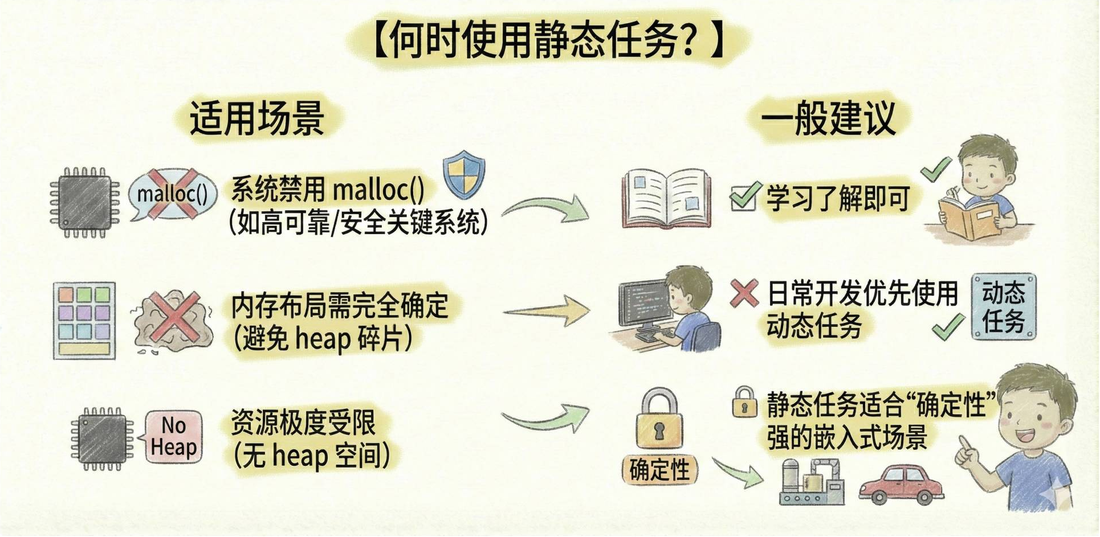

课件列出三类适用场景。

| 场景 | 使用静态任务的原因 |
|---|---|
| 系统禁止动态分配，例如有明确约束的高可靠或安全关键系统 | 创建任务时不从heap申请栈和控制块 |
| 需要确定的内存布局 | 提前规划任务存储，避免这部分动态分配带来的碎片问题 |
| 资源受限，没有可用heap空间 | 使用预留的栈数组和控制块存储，但仍需有足够RAM |

课件建议学习时了解静态任务，日常开发优先使用动态创建以减少手动管理代码。这是课程建议；实际项目按内存、生命周期及动态分配限制选择，不能仅由创建方式判断系统质量。

第二份PPT的小结强调：静态创建需要栈数组和TCB存储，配置 `configSUPPORT_STATIC_ALLOCATION`，按返回句柄或 `NULL` 判断创建结果；同时完成所需系统任务的内存回调。


## 16. FreeRTOS的核心可移植类型

第三份PPT从类型讲起。内核用统一类型名描述整数、节拍和栈元素，再由移植层定义其底层类型，从而屏蔽硬件差异。

| 类型 | 用途 | 本课Cortex-M示例中的底层类型 |
|---|---|---|
| `BaseType_t` | 适合当前架构处理的有符号整数，常用于状态值 | `long`，在当前32位ARM工具链上为32位 |
| `UBaseType_t` | 对应的无符号类型，常用于优先级、数量 | `unsigned long` |
| `TickType_t` | 系统tick计数及相关时间参数 | 课件写 `uint32_t` |
| `StackType_t` | 一个任务栈元素的类型 | `uint32_t` |

> 配置补充：参考Cortex-M4F端口中，`TickType_t` 受 `configUSE_16_BIT_TICKS` 控制，值为1时是 `uint16_t`，否则为 `uint32_t`。课件的32位表示对应配置，不是所有平台、所有配置的固定结论。类型宽度应查看当前端口与配置，而不是由名称猜测。

这也解释了为什么本篇反复按 `sizeof(StackType_t)` 换算栈容量，而不把“一个栈元素等于4字节”当成跨平台规则。


## 17. 变量前缀：从名称找到类型线索

课件采用匈牙利命名法的变体，将类型线索写在变量前缀中。

| 前缀 | 课件解释 | 示例 |
|---|---|---|
| `ul` | unsigned long | `ulCounter` |
| `us` | unsigned short | `usStackDepth` |
| `uc` | unsigned char | `ucPriority` |
| `px` | 指向非标准或自定义类型的指针，如结构体、句柄 | `pxTaskCode` |
| `pc` | 字符串指针；课件示例指向const char | `pcName` |
| `pv` | void通用指针 | `pvParameters` |
| `ux` | `UBaseType_t`，即无符号Base类型 | `uxPriority` |

`pxTaskCode` 的实际声明是 `TaskFunction_t`，因此它是**函数指针**，不是普通结构体指针；`pc` 提示字符指针，是否具有 `const` 限定仍须看声明。前缀帮助阅读，不会替代C类型系统。

课件还用句柄输出参数说明指针层次：

```c
TaskHandle_t * const pxCreatedTask;
```

`TaskHandle_t` 本身通常是指向内部任务对象的指针类型，`TaskHandle_t *` 则指向一个句柄变量。因此动态创建时使用 `&task1Handler`，内核把创建出的句柄写入这个变量。

声明中的末尾 `const` 限定的是 `pxCreatedTask` 这个指针变量，不表示禁止修改它指向的句柄。这与创建接口通过输出参数写回句柄的用途一致。


## 18. 函数前缀：返回类型必须结合声明

课件把函数前缀归纳为以下三类。

| 前缀 | 课件展示的返回类型 | 示例 |
|---|---|---|
| `x` | `BaseType_t`，常用于状态返回 | `xTaskCreate()` |
| `v` | `void`，无返回值 | `vTaskDelay()` |
| `pv` | `void *`，返回通用指针 | `pvTaskGetThreadLocalStoragePointer()` |

这些名称使阅读源码时更容易判断调用用途，但课件对 `x` 的解释需要结合实际接口。

| 本篇接口 | 实际返回值 | 成功判断 |
|---|---|---|
| `xTaskCreate()` | `BaseType_t` 状态码 | 返回 `pdPASS` |
| `xTaskCreateStatic()` | `TaskHandle_t` 句柄 | 返回值不是 `NULL` |
| `vTaskDelay()` | `void` | 没有返回值可用于成功判断 |

> 命名核对：`x` 不保证所有函数都返回 `BaseType_t`。本篇的 `xTaskCreateStatic()` 就返回任务句柄；`pdPASS/pdFAIL` 也不是所有接口统一的成功、失败返回值。判断方式以头文件声明和对应API说明为准。

本节只用 `pvTaskGetThreadLocalStoragePointer()` 说明前缀，不展开线程局部存储机制。


## 19. 宏前缀与课程小结

宏名称前缀用于提示所属模块和定义位置。

| 前缀 | 所属模块 | 课件示例 | 常见定义位置 |
|---|---|---|---|
| `config` | 用户配置 | `configMAX_PRIORITIES` | `FreeRTOSConfig.h` |
| `port` | 硬件移植层 | `portMAX_DELAY` | `portmacro.h` |
| `task` | 任务模块 | `taskENTER_CRITICAL()` | `task.h` |
| `pd` | 公共定义 | `pdTRUE`、`pdFALSE`、`pdPASS` | `projdefs.h` |

课件提醒，不清楚移植细节时不要随意修改 `port` 或 `pd` 开头的宏；应用功能开关和资源参数优先在 `FreeRTOSConfig.h` 中配置。本节的 `taskENTER_CRITICAL()` 只用于认识模块前缀，临界区的使用由后续课程展开。

命名规范这一课归纳为“类型 + 用途 + 模块归属”：变量前缀提供类型与语义线索，函数前缀提示返回值，宏前缀提示配置或模块位置。配合真实声明阅读，可以更快分辨参数、句柄和状态码，减少接口误用。

本篇依据三份PPT全部39页的图像与文字预览整理。省略各份课件的品牌尾页，以及命名PPT前四页残留的“环境准备”封面和模板占位内容；有效命名教学内容为第5—9页。原课教学图已裁去页眉、页脚并内嵌。

接口条件、名称容量和类型等必要核对参考官方 [FreeRTOS-Kernel V10.5.1](https://github.com/FreeRTOS/FreeRTOS-Kernel/tree/V10.5.1)，该版本只作参考，不代表课程代码版本已经确定。本笔记未进行开发板编译、下载或运行，不包含硬件实测结果。
